# 🔍 **EDA: опыление дикой черники (Wild Blueberry)**

**Датасет:** Wild Blueberry Pollination Simulation Data (Obsie, Qu, Drummond, University of Maine)
**Бизнес-задача:** «От чего зависит урожай черники?»

Ноутбук повторяет структуру разбора `Вебинар 2 eda_spotify.ipynb`: первичный осмотр → качество данных → одномерный анализ → взаимосвязи → сегменты → автоматический отчёт.

---

## 🎯 **Бизнес-кейс**

**Заказчик:** фермерское хозяйство, выращивающее дикую чернику.
**Вопрос:** какие условия дают высокий урожай и на что хозяйство может повлиять (например, завезти ульи или шмелей)?
**Аналог «хита» из Spotify:** поле с урожаем в верхних 25%.

## 📚 **Импорты и настройки**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

import phik  # добавляет метод df.phik_matrix()

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

---

# **Часть 1. Данные и контекст** 🫐

## **1.1 Откуда данные**

Данные не собраны в поле, а **сгенерированы моделью** Wild Blueberry Pollination Model (платформа GAMA). Модель откалибрована по 30 годам наблюдений в штате Мэн.
Проведено 77 700 прогонов симуляции, каждая из 777 строк — среднее по 100 прогонам.

**Следствие для EDA:** признаки — это заданные экспериментатором настройки, поэтому каждый принимает лишь несколько фиксированных значений (сетка эксперимента).

## **1.2 Загрузка данных**

In [2]:
from pathlib import Path

# Ищем корень проекта (папку с pyproject.toml), чтобы путь работал откуда угодно
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

df = pd.read_csv(ROOT / "data" / "raw" / "WildBlueberryPollinationSimulationData.csv")
print(f"Строк: {df.shape[0]}, столбцов: {df.shape[1]}")

Строк: 777, столбцов: 18


### 📋 Описание столбцов (по статье Data in Brief)

| Столбец | Единицы | Описание |
|---------|---------|----------|
| **Row#** | — | Номер строки (не признак) |
| **clonesize** | м² | Средний размер клона (куста) черники в поле |
| **honeybee** | пчёл/м²/мин | Плотность медоносных пчёл |
| **bumbles** | пчёл/м²/мин | Плотность шмелей |
| **andrena** | пчёл/м²/мин | Плотность пчёл-андрен |
| **osmia** | пчёл/м²/мин | Плотность пчёл-осмий |
| **MaxOfUpperTRange** | °F | Максимум верхней границы дневной температуры за цветение |
| **MinOfUpperTRange** | °F | Минимум верхней границы дневной температуры |
| **AverageOfUpperTRange** | °F | Среднее верхней границы дневной температуры |
| **MaxOfLowerTRange** | °F | Максимум нижней границы дневной температуры |
| **MinOfLowerTRange** | °F | Минимум нижней границы дневной температуры |
| **AverageOfLowerTRange** | °F | Среднее нижней границы дневной температуры |
| **RainingDays** | дни | Число дождливых дней за цветение |
| **AverageRainingDays** | — | Доля дождливых дней за цветение |
| **fruitset** | доля | Завязываемость плодов (результат опыления) |
| **fruitmass** | г | Масса плода (результат) |
| **seeds** | шт | Число семян в ягоде (результат) |
| **yield** | — | **Урожай — целевая переменная** |

⚠️ В статье температуры подписаны как ℃, но значения 39–95 возможны только в **°F** (95 ℃ — почти кипяток).

---

# **Часть 2. Первичный осмотр данных** 📀

## **2.1 Первый взгляд**

In [3]:
df.head()

,Row#,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
0,0,37.5,0.75,0.25,0.25,0.25,86.0,52.0,71.9,62.0,30.0,50.8,16.0,0.26,0.410652,0.408159,31.678898,3813.165795
1,1,37.5,0.75,0.25,0.25,0.25,86.0,52.0,71.9,62.0,30.0,50.8,1.0,0.10,0.444254,0.425458,33.449385,4947.605663
2,2,37.5,0.75,0.25,0.25,0.25,94.6,57.2,79.0,68.2,33.0,55.9,16.0,0.26,0.383787,0.399172,30.546306,3866.798965
3,3,37.5,0.75,0.25,0.25,0.25,94.6,57.2,79.0,68.2,33.0,55.9,1.0,0.10,0.407564,0.408789,31.562586,4303.943030
4,4,37.5,0.75,0.25,0.25,0.25,86.0,52.0,71.9,62.0,30.0,50.8,24.0,0.39,0.354413,0.382703,28.873714,3436.493543


In [4]:
# Случайная выборка — смотрим разные срезы
df.sample(5, random_state=42)

,Row#,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
568,568,25.0,0.50,0.25,0.63,0.50,69.7,42.1,58.2,50.2,24.3,41.2,34.0,0.56,0.388956,0.376880,29.284336,4282.700632
530,530,25.0,0.50,0.25,0.50,0.63,77.4,46.8,64.7,55.8,27.0,45.8,1.0,0.10,0.532729,0.466475,38.060375,6801.492050
610,610,25.0,0.50,0.25,0.75,0.50,77.4,46.8,64.7,55.8,27.0,45.8,1.0,0.10,0.510669,0.452680,36.386359,6279.338501
109,109,12.5,0.25,0.25,0.25,0.63,69.7,42.1,58.2,50.2,24.3,41.2,16.0,0.26,0.546136,0.453001,37.970243,6898.390949
586,586,25.0,0.50,0.25,0.63,0.75,86.0,52.0,71.9,62.0,30.0,50.8,1.0,0.10,0.542164,0.471829,38.705696,7004.015537


## **2.2 Технический паспорт**

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 777 entries, 0 to 776
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Row#                  777 non-null    int64  
 1   clonesize             777 non-null    float64
 2   honeybee              777 non-null    float64
 3   bumbles               777 non-null    float64
 4   andrena               777 non-null    float64
 5   osmia                 777 non-null    float64
 6   MaxOfUpperTRange      777 non-null    float64
 7   MinOfUpperTRange      777 non-null    float64
 8   AverageOfUpperTRange  777 non-null    float64
 9   MaxOfLowerTRange      777 non-null    float64
 10  MinOfLowerTRange      777 non-null    float64
 11  AverageOfLowerTRange  777 non-null    float64
 12  RainingDays           777 non-null    float64
 13  AverageRainingDays    777 non-null    float64
 14  fruitset              777 non-null    float64
 15  fruitmass             777 non-null

### Анализ `.info()`:

| Метрика | Значение | Вывод |
|---------|----------|-------|
| **Типы данных** | все числовые (float64 + int64 для Row#) | Категориальных столбцов нет |
| **Пропуски** | non-null = 777 во всех столбцах | Пропусков нет |

## **2.3 Оптимизация памяти**

In [6]:
memory_before = df.memory_usage(deep=True).sum() / 1024
print(f"💾 Память до: {memory_before:.1f} KB")

for col in df.select_dtypes(include="int64").columns:
    df[col] = pd.to_numeric(df[col], downcast="integer")
for col in df.select_dtypes(include="float64").columns:
    df[col] = pd.to_numeric(df[col], downcast="float")

memory_after = df.memory_usage(deep=True).sum() / 1024
print(f"💾 Память после: {memory_after:.1f} KB (экономия {(1 - memory_after / memory_before) * 100:.0f}%)")

💾 Память до: 109.4 KB
💾 Память после: 53.2 KB (экономия 51%)


Датасет крошечный (777 строк), поэтому оптимизация здесь — скорее упражнение. Для расчётов float32 точности хватает с запасом.

## **2.4 Статистическая сводка**

In [7]:
df.drop(columns='Row#').describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
clonesize,777.0,18.768,6.999,10.000,12.500,12.500,25.000,40.000
honeybee,777.0,0.417,0.979,0.000,0.250,0.250,0.500,18.430
bumbles,777.0,0.282,0.066,0.000,0.250,0.250,0.380,0.585
andrena,777.0,0.469,0.161,0.000,0.380,0.500,0.630,0.750
osmia,777.0,0.562,0.169,0.000,0.500,0.630,0.750,0.750
MaxOfUpperTRange,777.0,82.277,9.194,69.700,77.400,86.000,89.000,94.600
MinOfUpperTRange,777.0,49.701,5.596,39.000,46.800,52.000,52.000,57.200
AverageOfUpperTRange,777.0,68.723,7.677,58.200,64.700,71.900,71.900,79.000
MaxOfLowerTRange,777.0,59.309,6.648,50.200,55.800,62.000,66.000,68.200
MinOfLowerTRange,777.0,28.690,3.210,24.300,27.000,30.000,30.000,33.000


**Что бросается в глаза:**
- `honeybee`: среднее 0.42, а максимум 18.43 — очень длинный правый хвост.
- У большинства признаков медиана совпадает с квартилями (например, `clonesize`: 25% = медиана = 12.5) — признак принимает мало значений.

## **2.5 Сетка эксперимента: число уникальных значений**

In [8]:
nunique = df.drop(columns='Row#').nunique().sort_values()
nunique.to_frame('Уникальных значений')

,Уникальных значений
MaxOfLowerTRange,5
AverageRainingDays,5
RainingDays,5
AverageOfLowerTRange,5
MinOfLowerTRange,5
MaxOfUpperTRange,5
MinOfUpperTRange,5
AverageOfUpperTRange,5
clonesize,6
honeybee,7


In [9]:
# Какие именно значения принимают «настроечные» признаки
for col in ['clonesize', 'honeybee', 'RainingDays', 'AverageOfUpperTRange']:
    print(f"{col}:")
    print(df[col].value_counts().sort_index().to_string(), "\n")

clonesize:
clonesize
10.0      1
12.5    406
20.0     16
25.0    328
37.5     25
40.0      1 

honeybee:
honeybee
0.000       8
0.250     446
0.500     302
0.537       6
0.750      11
6.640       2
18.430      2 

RainingDays:
RainingDays
1.00     192
3.77      16
16.00    194
24.00    188
34.00    187 

AverageOfUpperTRange:
AverageOfUpperTRange
58.200001    181
64.699997    188
65.599998      2
71.900002    212
79.000000    194 



### 🔍 **Важное наблюдение:** это не наблюдения, а план эксперимента

| Группа | Уникальных значений | Смысл |
|--------|--------------------|-------|
| Температуры, дожди | 5 | 5 «сценариев погоды» |
| `clonesize` | 6 | в основном 12.5, 25 и 37.5 |
| Пчёлы | 7–12 | несколько уровней плотности |
| `fruitset`, `fruitmass`, `seeds`, `yield` | ~777 | **результаты** симуляции |

Как и с жанрами в Spotify, `value_counts()` здесь показывает **структуру эксперимента**, а не то, «как бывает в природе».

---

# **Часть 3. Качество данных** 🧹

## **3.1 Пропуски**

In [10]:
missing = df.isna().sum()
print(f"📊 Всего пропусков: {missing.sum()}")

📊 Всего пропусков: 0


**Вывод:** пропусков нет — симуляция выдаёт полную таблицу.

## **3.2 Дубликаты**

In [11]:
features_in = ['clonesize', 'honeybee', 'bumbles', 'andrena', 'osmia',
               'MaxOfUpperTRange', 'MinOfUpperTRange', 'AverageOfUpperTRange',
               'MaxOfLowerTRange', 'MinOfLowerTRange', 'AverageOfLowerTRange',
               'RainingDays', 'AverageRainingDays']

print(f"🔁 Полных дубликатов (без Row#): {df.drop(columns='Row#').duplicated().sum()}")
print(f"🔁 Строк с одинаковыми входными условиями: {df.duplicated(subset=features_in).sum()}")

🔁 Полных дубликатов (без Row#): 0
🔁 Строк с одинаковыми входными условиями: 0


**Вывод:** дубликатов нет — каждая строка соответствует своей комбинации условий.

## **3.3 Выбросы**

### **Визуальный метод: boxplot**

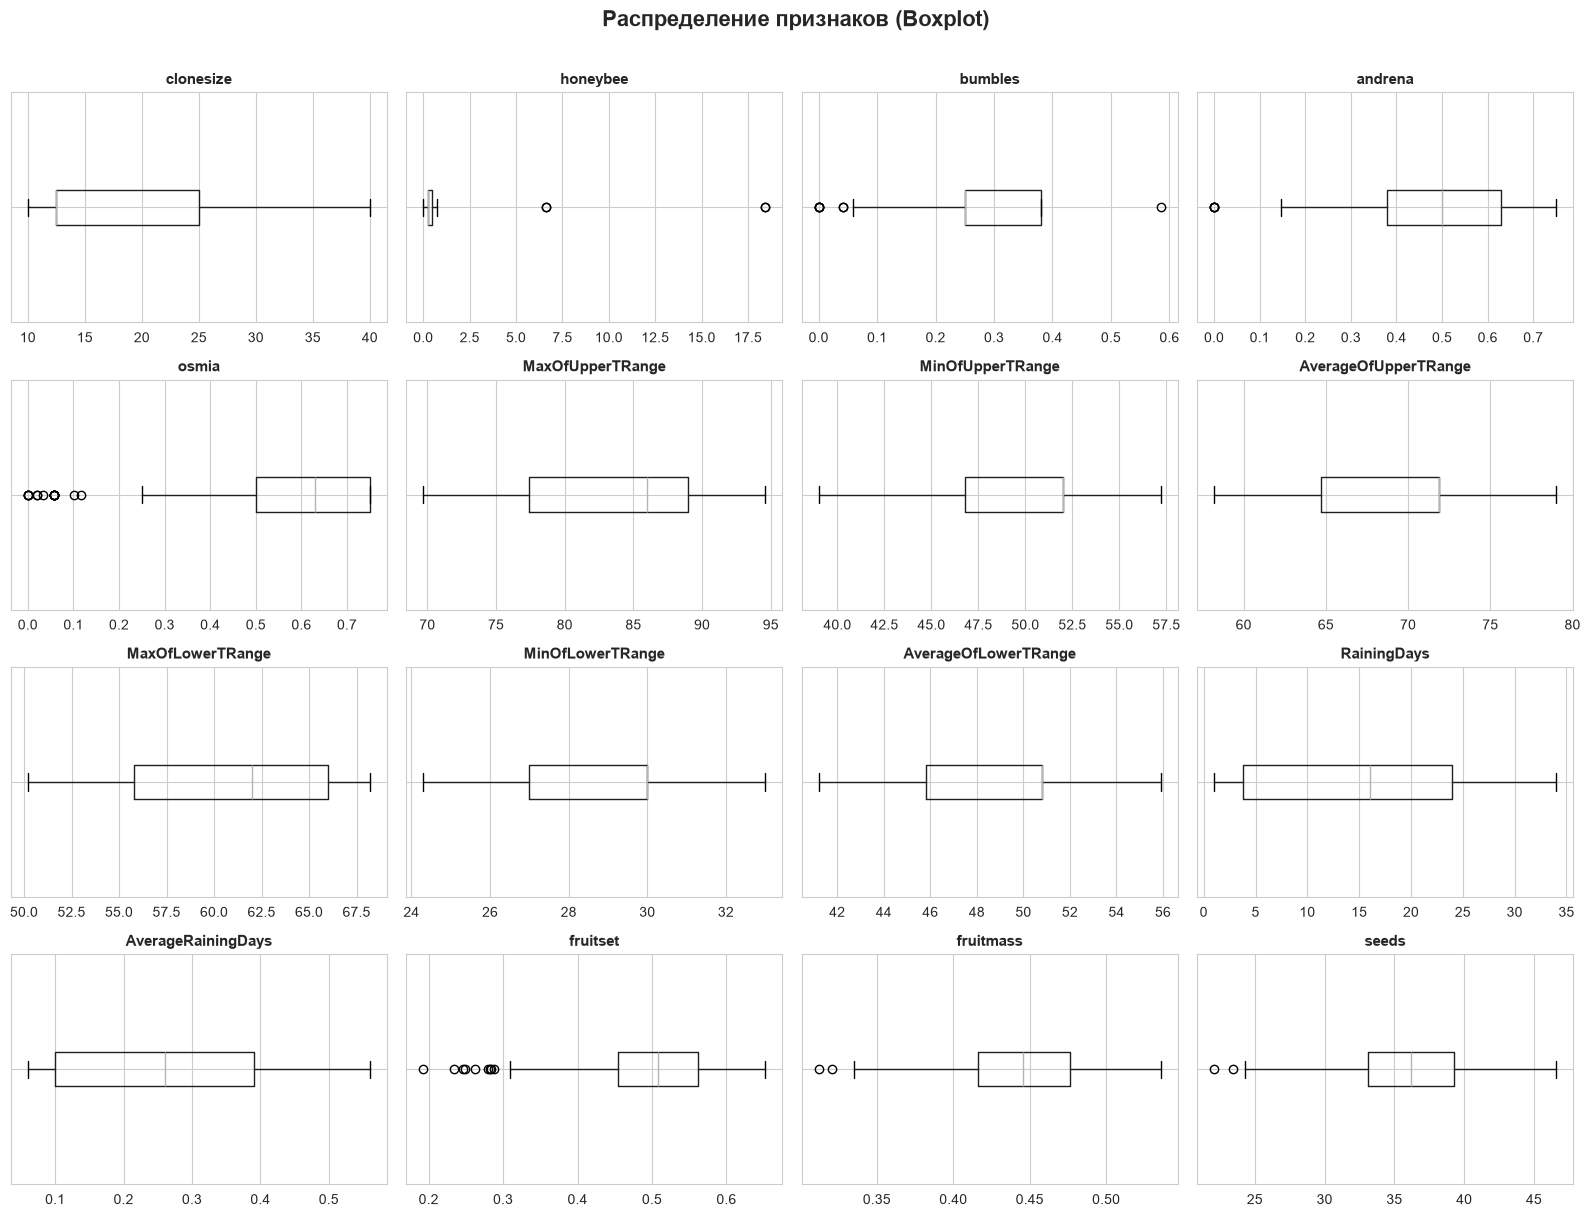

In [12]:
plot_cols = df.drop(columns='Row#').columns

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.flatten(), plot_cols):
    df.boxplot(column=col, ax=ax, vert=False)
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_yticklabels([])
for ax in axes.flatten()[len(plot_cols):]:
    ax.set_visible(False)

plt.suptitle('Распределение признаков (Boxplot)', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 🔍 **Анализ выбросов:**

| Признак | Что видно | Интерпретация |
|---------|-----------|---------------|
| **honeybee** | Значения 6.64 и 18.43 | Сценарии «привезли ульи» — экстремальная плотность пчёл |
| **bumbles, andrena, osmia** | Точки около 0 | Сценарии без отдельных видов опылителей |
| **fruitset, yield** | Низкие значения | Поля с плохим опылением |

### **Проверка аномалий**

In [13]:
bees = ['honeybee', 'bumbles', 'andrena', 'osmia']

extreme_honeybee = df[df['honeybee'] > 1]
print(f"🐝 Строк с honeybee > 1: {len(extreme_honeybee)}")
display(extreme_honeybee)

zero_bees = df[(df[bees] == 0).any(axis=1)]
print(f"\n🚫 Строк, где хотя бы один вид пчёл = 0: {len(zero_bees)}")
display(zero_bees)

🐝 Строк с honeybee > 1: 4


,Row#,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
761,761,20.0,6.64,0.000,0.000,0.000,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.508675,0.336240,24.601742,4936.364746
762,762,20.0,18.43,0.000,0.000,0.000,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.559628,0.364937,27.106392,6131.309570
763,763,20.0,6.64,0.065,0.229,0.033,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.539256,0.382997,28.887119,5686.122070
765,765,20.0,18.43,0.042,0.147,0.021,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.557885,0.377597,28.556417,6276.410645



🚫 Строк, где хотя бы один вид пчёл = 0: 10


,Row#,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
759,759,20.0,0.00,0.117,0.409,0.058,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.380852,0.396044,30.052521,3923.906250
760,760,20.0,0.00,0.202,0.707,0.101,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.492760,0.443520,35.311958,5718.408203
761,761,20.0,6.64,0.000,0.000,0.000,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.508675,0.336240,24.601742,4936.364746
762,762,20.0,18.43,0.000,0.000,0.000,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.559628,0.364937,27.106392,6131.309570
766,766,20.0,0.00,0.042,0.147,0.021,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.192732,0.311921,22.079199,1637.703979
767,767,20.0,0.00,0.585,0.000,0.000,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.599984,0.529791,46.585106,7575.801270
768,768,20.0,0.00,0.000,0.585,0.000,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.249335,0.320727,23.412775,2605.696777
769,769,20.0,0.00,0.000,0.000,0.585,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.361519,0.389815,29.559494,4254.825195
770,770,20.0,0.00,0.293,0.234,0.058,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.497503,0.453339,36.633377,5449.421387
771,771,20.0,0.00,0.058,0.409,0.117,86.0,52.0,71.900002,62.0,30.0,50.799999,3.77,0.06,0.335927,0.377012,28.135899,3471.192139


Все аномальные строки собраны в **конце файла** (Row# ≥ 759) и выглядят как отдельная серия экспериментов. Проверим, чем этот блок отличается от остальных.

In [14]:
# Основная сетка эксперимента — clonesize 12.5, 25 и 37.5
main_grid = df['clonesize'].isin([12.5, 25, 37.5])
special = df[~main_grid]

print(f"📦 Основная сетка: {main_grid.sum()} строк")
print(f"🧪 Особый блок: {len(special)} строк, Row# {special['Row#'].min()}–{special['Row#'].max()}")
print("\nЗначения в особом блоке:")
for col in ['clonesize', 'RainingDays', 'AverageOfUpperTRange']:
    print(f"  {col}: {sorted(special[col].unique().tolist())}")

📦 Основная сетка: 759 строк
🧪 Особый блок: 18 строк, Row# 759–776

Значения в особом блоке:
  clonesize: [10.0, 20.0, 40.0]
  RainingDays: [3.7699999809265137, 24.0]
  AverageOfUpperTRange: [65.5999984741211, 71.9000015258789]


### **Решение по особому блоку**

18 строк особого блока используют условия, которых **нет в основной сетке**: `clonesize` 10/20/40, 3.77 дождливых дня, температура 65.6 °F, экстремальные и нулевые плотности пчёл.
Это аналог жанра `sleep` в Spotify: данные корректны, но описывают «другой мир».

**Наш выбор:** для основного анализа берём сетку (`df_clean`), особый блок не удаляем навсегда, а держим в `df` для справки.

In [15]:
df_clean = df[main_grid].drop(columns='Row#').reset_index(drop=True)
print(f"📊 Размер df_clean: {len(df_clean)} строк")

📊 Размер df_clean: 759 строк


## **3.4 Избыточные признаки (мультиколлинеарность)**

Шесть температурных столбцов и два столбца про дожди описывают одно и то же. Проверим.

In [16]:
temp_cols = ['MaxOfUpperTRange', 'MinOfUpperTRange', 'AverageOfUpperTRange',
             'MaxOfLowerTRange', 'MinOfLowerTRange', 'AverageOfLowerTRange']

print(f"🌡️ Минимальная корреляция между температурами: {df_clean[temp_cols].corr().min().min():.3f}")
print(f"🌧️ Корреляция RainingDays и AverageRainingDays: {df_clean['RainingDays'].corr(df_clean['AverageRainingDays']):.3f}")

🌡️ Минимальная корреляция между температурами: 1.000
🌧️ Корреляция RainingDays и AverageRainingDays: 0.992


**Вывод:** все температуры коррелируют почти на 100% — это **один** фактор «тёплый/холодный сезон». Дожди — тоже один фактор.
Для анализа оставляем по одному представителю: `AverageOfUpperTRange` и `RainingDays`.

## **3.5 Утечка целевой переменной**

`fruitset`, `fruitmass` и `seeds` — это **результаты** той же симуляции, что и `yield`. Их нельзя использовать как «причины» урожая: на момент планирования сезона они неизвестны.

In [17]:
outcomes = ['fruitset', 'fruitmass', 'seeds']
df_clean[outcomes + ['yield']].corr()['yield'].round(3)

fruitset     0.985
fruitmass    0.936
seeds        0.970
yield        1.000
Name: yield, dtype: float64

In [18]:
# Факторы, на которые можно опираться при анализе
factors = ['clonesize', 'honeybee', 'bumbles', 'andrena', 'osmia',
           'AverageOfUpperTRange', 'RainingDays']

### **Какой набор данных использовать?**
- **df_clean + factors** — для поиска причин урожая.
- **df_clean + outcomes** — для понимания механизма (урожай = завязь × масса ягоды).
- **df** — если нужны экстремальные сценарии с пчёлами.

---

# **Часть 4. Одномерный анализ** 📊

## **4.1 Распределение урожая (целевая переменная)**

/var/folders/75/vry_7ppx39l3fh95dgsd7ygm0000gn/T/ipykernel_48618/2852489316.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax2_box.boxplot(df_clean['yield'], vert=False, widths=0.3, positions=[0.5])


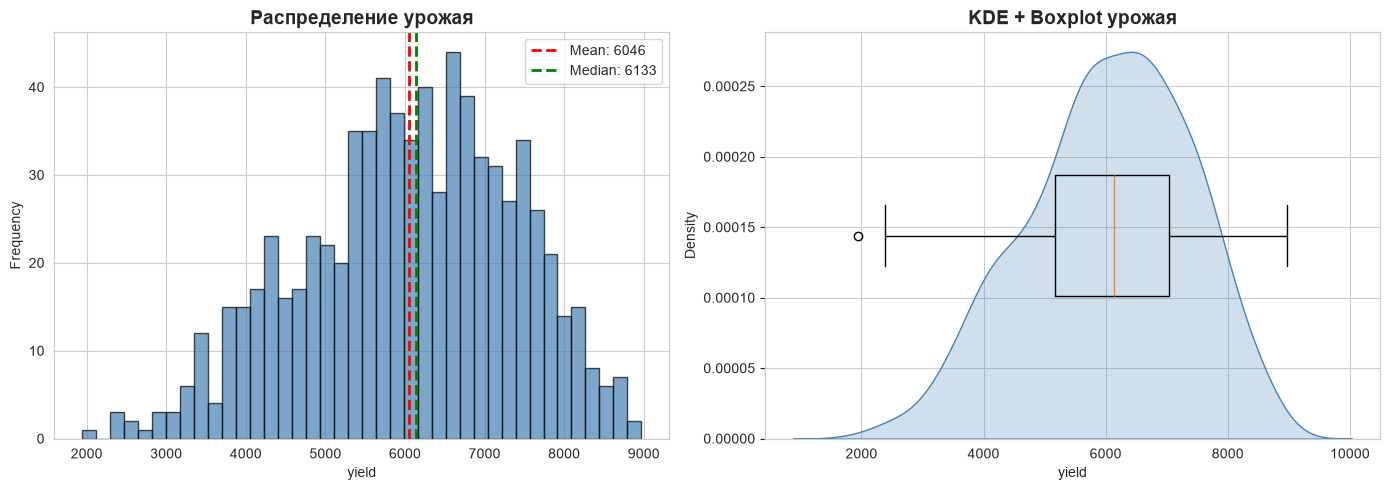

Асимметрия (skew): -0.31


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
df_clean['yield'].hist(bins=40, ax=ax1, color='steelblue', edgecolor='black', alpha=0.7)
ax1.axvline(df_clean['yield'].mean(), color='red', linestyle='--', linewidth=2,
            label=f"Mean: {df_clean['yield'].mean():.0f}")
ax1.axvline(df_clean['yield'].median(), color='green', linestyle='--', linewidth=2,
            label=f"Median: {df_clean['yield'].median():.0f}")
ax1.set_xlabel('yield')
ax1.set_ylabel('Frequency')
ax1.set_title('Распределение урожая', fontsize=14, fontweight='bold')
ax1.legend()

ax2 = axes[1]
sns.kdeplot(df_clean['yield'], ax=ax2, fill=True, color='steelblue')
ax2_box = ax2.twinx()
ax2_box.boxplot(df_clean['yield'], vert=False, widths=0.3, positions=[0.5])
ax2_box.set_yticks([])
ax2.set_title('KDE + Boxplot урожая', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Асимметрия (skew): {df_clean['yield'].skew():.2f}")

Распределение близко к нормальному с лёгким хвостом влево: есть немного полей с очень низким урожаем.

## **4.2 Распределение факторов**

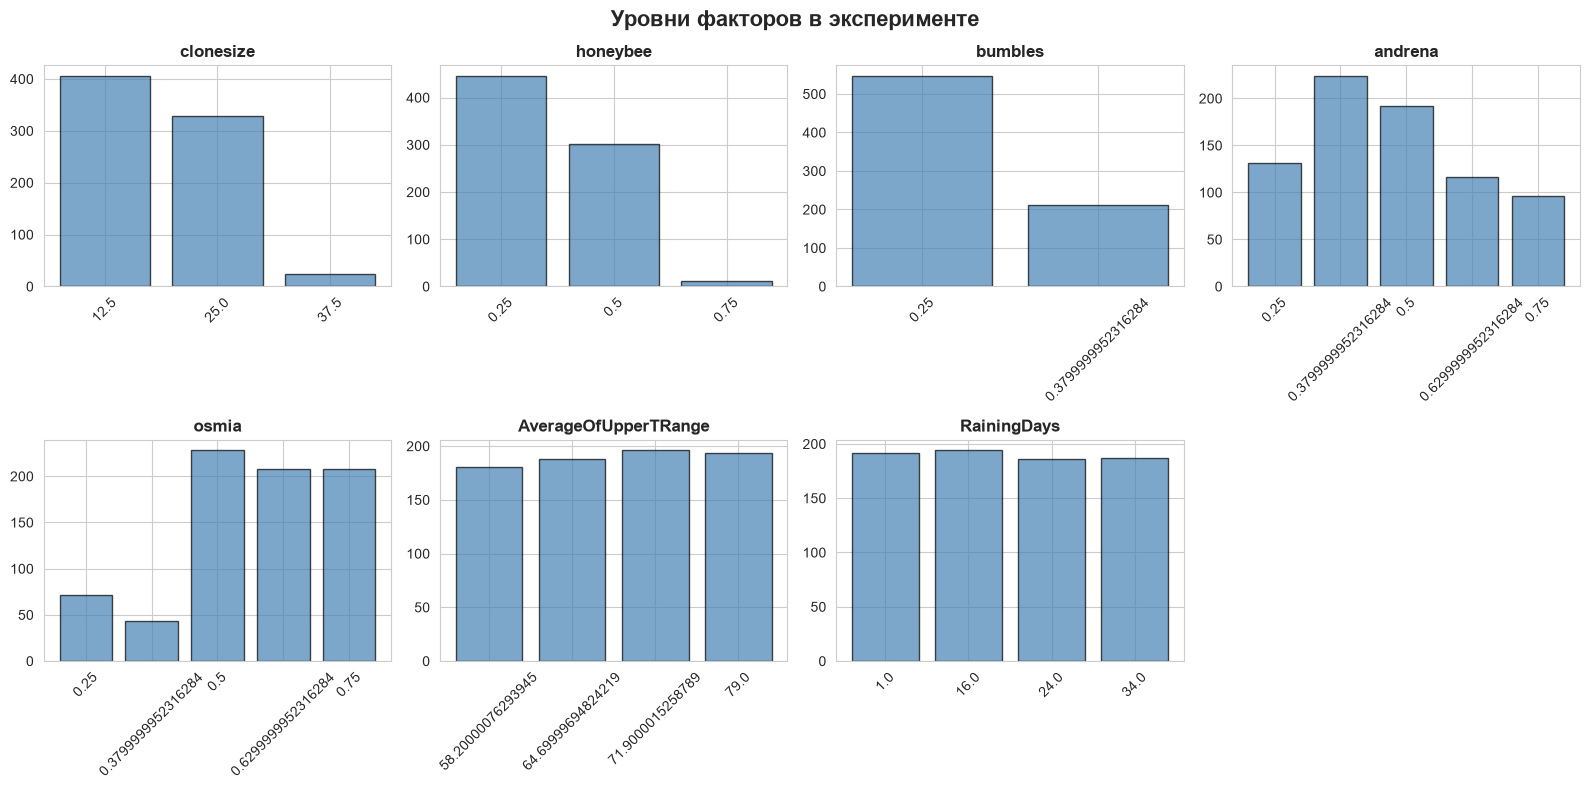

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), factors):
    counts = df_clean[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color='steelblue', edgecolor='black', alpha=0.7)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
axes.flatten()[-1].set_visible(False)

plt.suptitle('Уровни факторов в эксперименте', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

Факторы дискретные, поэтому вместо гистограмм — столбики по уровням.
Уровни встречаются **неравномерно**: например, `clonesize = 37.5` — всего 25 строк. Выводы по редким уровням менее надёжны.

## **4.3 Распределение результатов опыления**

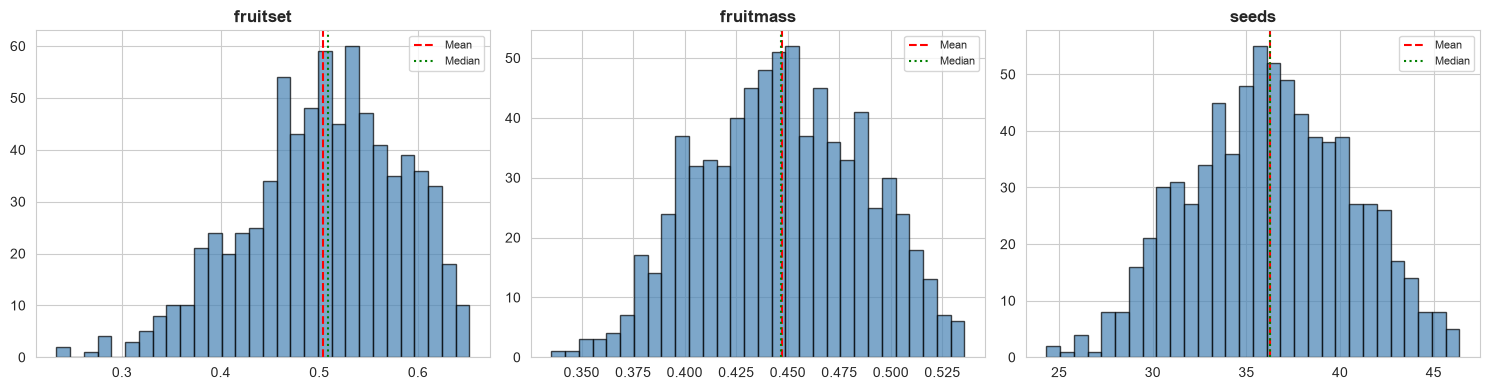

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, outcomes):
    df_clean[col].hist(bins=30, ax=ax, color='steelblue', edgecolor='black', alpha=0.7)
    ax.axvline(df_clean[col].mean(), color='red', linestyle='--', label='Mean')
    ax.axvline(df_clean[col].median(), color='green', linestyle=':', label='Median')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

---

# **Часть 5. Многомерный анализ** 🔗

## **5.1 Визуальный анализ (pairplot)**

**Принцип EDA:** сначала смотрим, потом считаем.

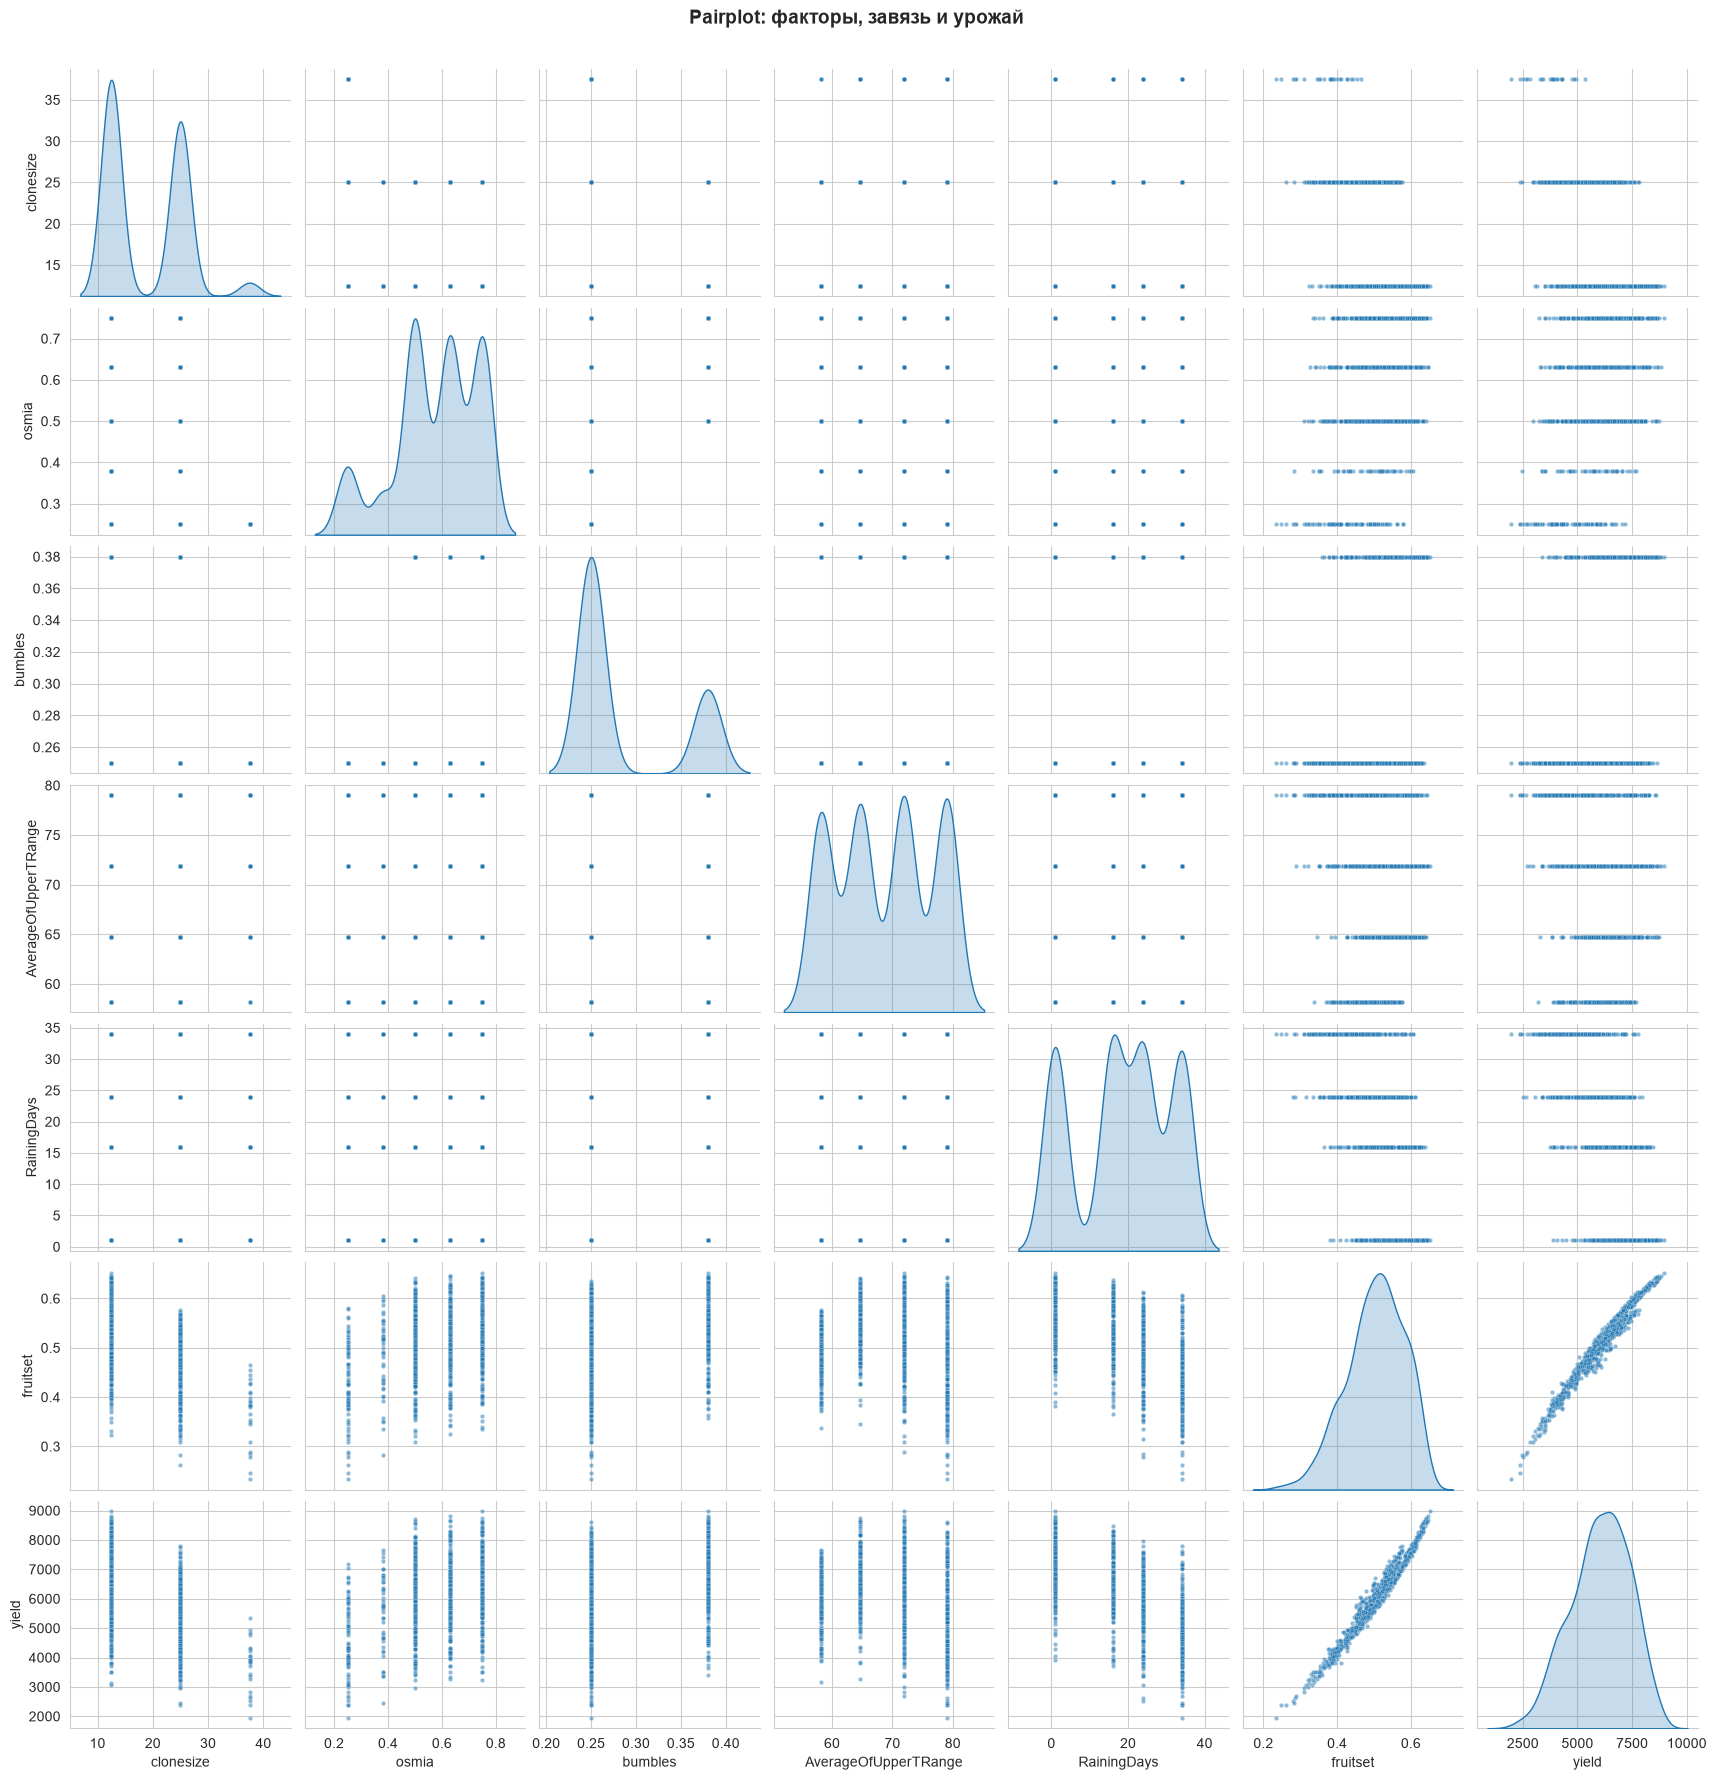

In [22]:
sns.pairplot(df_clean[['clonesize', 'osmia', 'bumbles', 'AverageOfUpperTRange',
                       'RainingDays', 'fruitset', 'yield']],
             diag_kind='kde', plot_kws={'alpha': 0.5, 's': 10})
plt.suptitle('Pairplot: факторы, завязь и урожай', fontsize=14, fontweight='bold', y=1.02)
plt.show()

- `fruitset` и `yield` лежат почти на прямой — урожай почти полностью определяется завязью.
- По факторам точки выстроены «столбиками» (уровни эксперимента); видно, что больше дождей и крупнее клон → ниже урожай.

## **5.2 Корреляции φk (phik)**

Как и в разборе Spotify, используем φk: он ловит нелинейные связи. Все наши признаки числовые, поэтому передаём их в `interval_cols`.

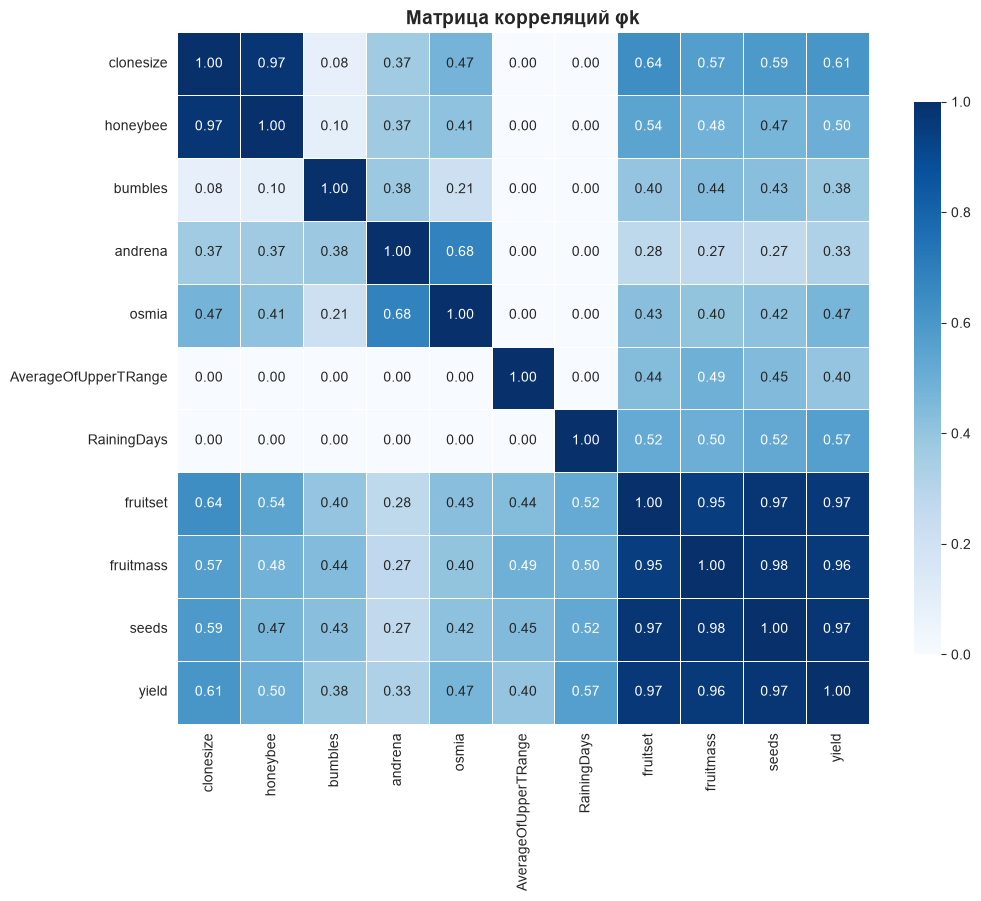

In [23]:
phik_cols = factors + outcomes + ['yield']
phik_matrix = df_clean[phik_cols].phik_matrix(interval_cols=phik_cols)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(phik_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
            square=True, linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Матрица корреляций φk', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

φk показывает **силу** связи, но не её **направление**. Направление смотрим по Пирсону.

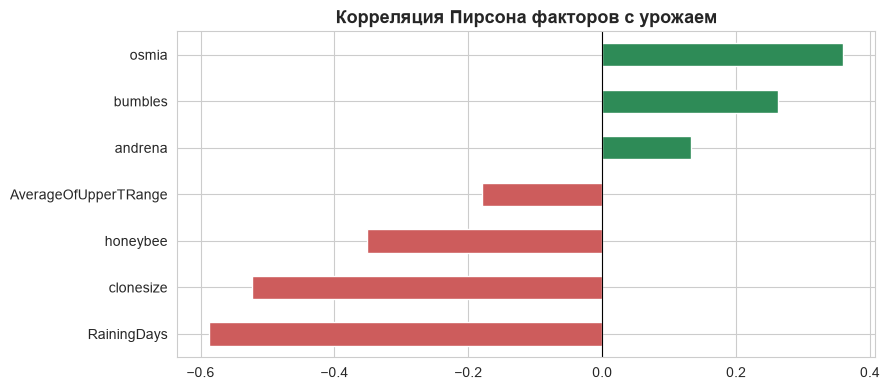

RainingDays            -0.587
clonesize              -0.523
honeybee               -0.351
AverageOfUpperTRange   -0.180
andrena                 0.132
bumbles                 0.262
osmia                   0.360
Name: yield, dtype: float64

In [24]:
pearson = df_clean[factors + ['yield']].corr()['yield'].drop('yield').sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
pearson.plot(kind='barh', ax=ax, color=['indianred' if v < 0 else 'seagreen' for v in pearson])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Корреляция Пирсона факторов с урожаем', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

pearson.round(3)

### 💡 **Первые выводы:**
- Урожай сильнее всего связан с **дождями** и **размером клона** — обе связи отрицательные.
- **Осмии** и **шмели** — положительная связь.
- **Медоносная пчела** — отрицательная связь?! Неужели пчёлы вредят урожаю? Проверим.

## **5.3 Ловушка: смешение факторов**

В плане эксперимента плотность медоносных пчёл задавалась **вместе** с размером клона.

In [25]:
pd.crosstab(df_clean['clonesize'], df_clean['honeybee'])

honeybee,0.25,0.50,0.75
clonesize,,,
12.5,406,0,0
25.0,26,302,0
37.5,14,0,11


При клоне 12.5 пчёл всегда 0.25, при клоне 25 — почти всегда 0.5. Значит, «больше пчёл» в общей корреляции на самом деле означает «крупнее клон».
Сравним поля **с одинаковым** размером клона:

In [26]:
within = (df_clean[df_clean['clonesize'] == 25]
          .groupby('honeybee')['yield'].agg(['count', 'median']).round(0))
print("Клон 25 м²: урожай при разной плотности медоносных пчёл")
display(within)

corr_25 = df_clean[df_clean['clonesize'] == 25][['honeybee', 'yield']].corr().iloc[0, 1]
print(f"Корреляция honeybee и yield внутри клона 25: {corr_25:+.2f}")

Клон 25 м²: урожай при разной плотности медоносных пчёл


,count,median
honeybee,,
0.25,26,4417.0
0.50,302,5736.0


Корреляция honeybee и yield внутри клона 25: +0.32


### 💡 **Ключевой инсайт:**
При одинаковом клоне **больше медоносных пчёл → выше урожай**. Отрицательная общая корреляция — артефакт плана эксперимента.

**Урок EDA:** корреляция по всей таблице может врать, если факторы задавались не независимо. Всегда проверяйте связь внутри сегментов.

---

# **Часть 6. Сегментированный анализ** 🫐

## **6.1 Урожай по сегментам**

Аналог жанров в Spotify — уровни факторов. Сравним урожай по размеру клона и погоде.

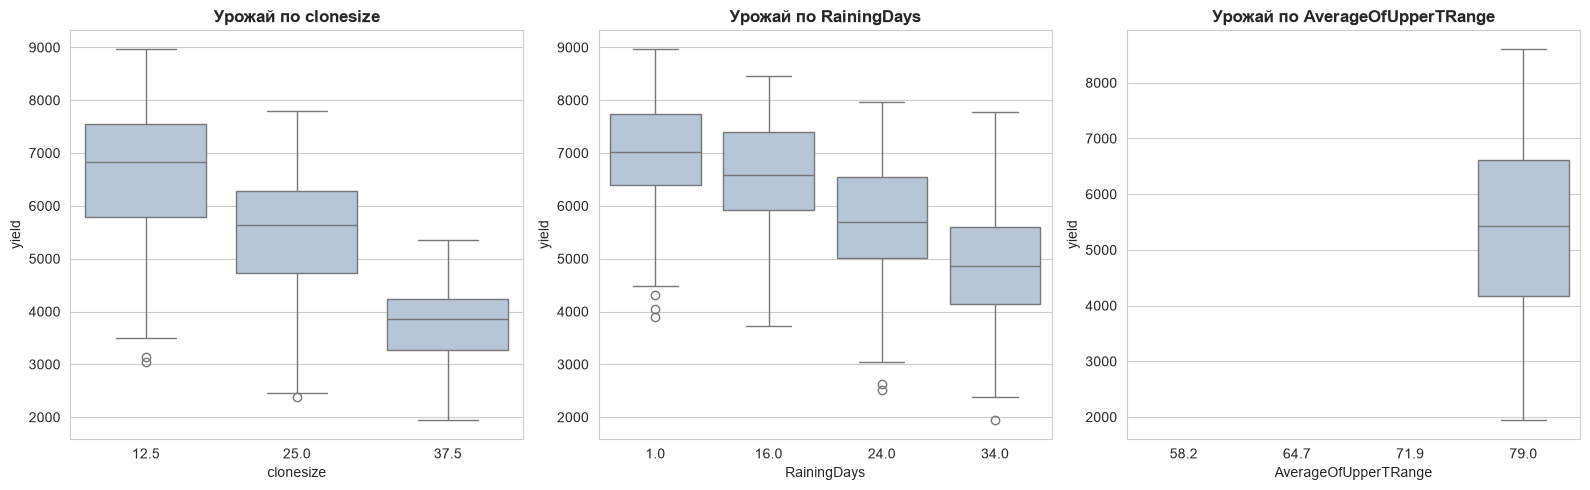

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ['clonesize', 'RainingDays', 'AverageOfUpperTRange']):
    sns.boxplot(data=df_clean, x=col, y='yield', ax=ax, color='lightsteelblue')
    ax.set_title(f'Урожай по {col}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

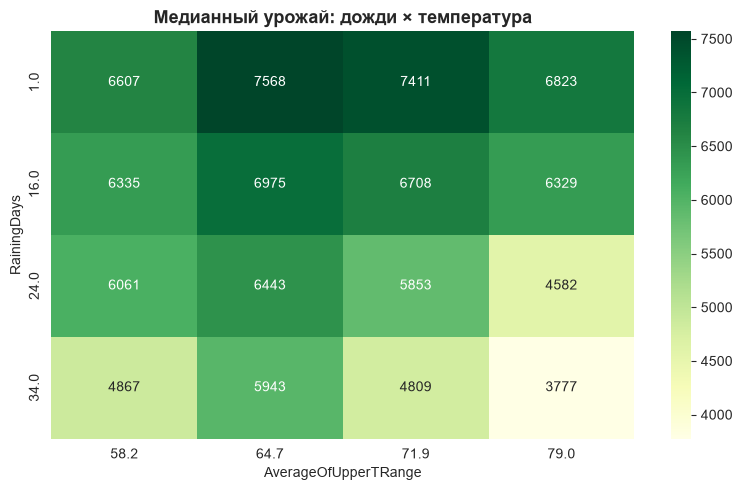

In [28]:
# Совместное влияние погоды: медианный урожай
pivot = df_clean.pivot_table(index='RainingDays', columns='AverageOfUpperTRange',
                             values='yield', aggfunc='median')

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlGn', ax=ax)
ax.set_title('Медианный урожай: дожди × температура', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## **6.2 «Что даёт высокий урожай?»** 🎯

Аналог «хита»: поле с урожаем в верхних 25%.

In [29]:
high_threshold = df_clean['yield'].quantile(0.75)
df_clean['is_high'] = (df_clean['yield'] >= high_threshold).astype(int)

print(f"🎯 Порог высокого урожая: yield >= {high_threshold:.0f}")
print(df_clean['is_high'].value_counts())
print(f"\nДоля высоких: {df_clean['is_high'].mean() * 100:.1f}%")

🎯 Порог высокого урожая: yield >= 7043
is_high
0    569
1    190
Name: count, dtype: int64

Доля высоких: 25.0%


## **6.3 Высокий урожай vs остальные**

In [30]:
compare_cols = factors + outcomes
high_comparison = df_clean.groupby('is_high')[compare_cols].median().T
high_comparison.columns = ['Обычные поля', 'Высокий урожай']
high_comparison['Разница'] = high_comparison['Высокий урожай'] - high_comparison['Обычные поля']
high_comparison['Разница %'] = ((high_comparison['Высокий урожай'] / high_comparison['Обычные поля'] - 1) * 100).round(1)
high_comparison.round(3)

,Обычные поля,Высокий урожай,Разница,Разница %
clonesize,25.000000,12.500000,-12.500,-50.000000
honeybee,0.500000,0.250000,-0.250,-50.000000
bumbles,0.250000,0.250000,0.000,0.000000
andrena,0.500000,0.500000,0.000,0.000000
osmia,0.630000,0.630000,0.000,0.000000
AverageOfUpperTRange,71.900002,68.300003,-3.600,-5.000000
RainingDays,24.000000,16.000000,-8.000,-33.299999
fruitset,0.484000,0.597000,0.113,23.400000
fruitmass,0.434000,0.496000,0.062,14.300000
seeds,34.863998,41.505001,6.642,19.100000


### 🎨 **Radar Chart «Профиль высокого урожая»**

Факторы в разных единицах, поэтому перед radar chart нормируем их в диапазон 0–1 (min-max).
Берём **средние**, а не медианы: у дискретных признаков медианы двух групп часто совпадают и скрывают разницу.

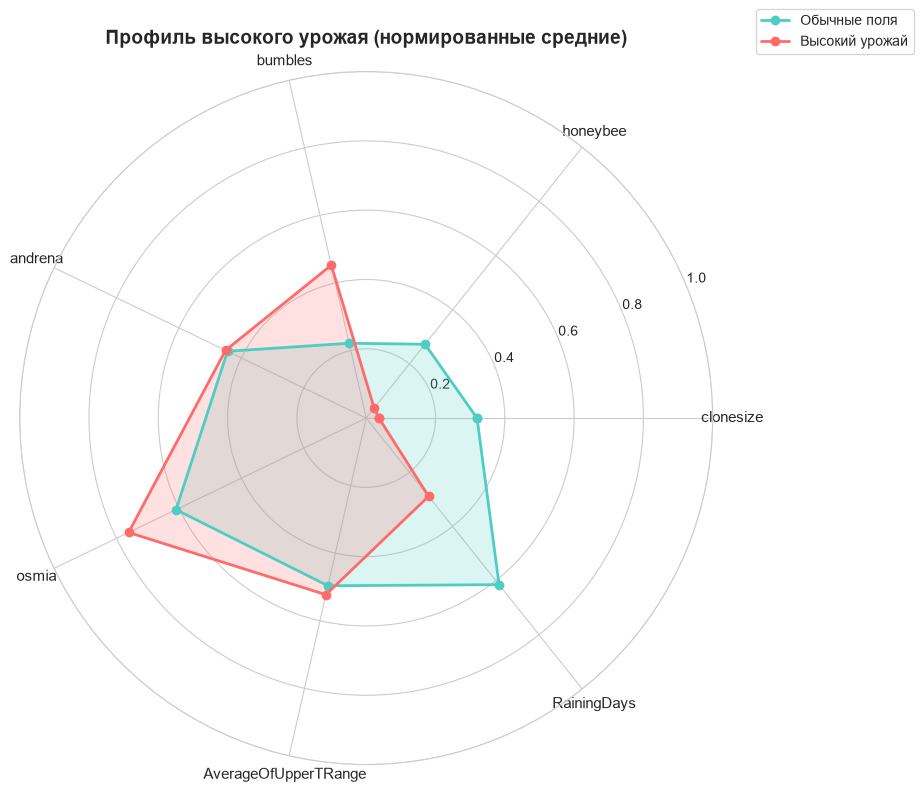

In [31]:
norm = df_clean[factors].copy()
norm = (norm - norm.min()) / (norm.max() - norm.min())
norm['is_high'] = df_clean['is_high']
profile_stats = norm.groupby('is_high')[factors].mean()

N = len(factors)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
for label, name, color in [(0, 'Обычные поля', '#4ECDC4'), (1, 'Высокий урожай', '#FF6B6B')]:
    values = profile_stats.loc[label].tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=name, color=color)
    ax.fill(angles, values, alpha=0.2, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(factors, fontsize=11)
ax.set_ylim(0, 1)
ax.set_title('Профиль высокого урожая (нормированные средние)', fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

## **6.4 Профили опылителей по размеру клона**

In [32]:
clone_bees = df_clean.groupby('clonesize')[bees + ['yield']].mean().round(3)
clone_bees['строк'] = df_clean['clonesize'].value_counts().sort_index()
clone_bees

,honeybee,bumbles,andrena,osmia,yield,строк
clonesize,,,,,,
12.5,0.25,0.283,0.460,0.576,6637.759766,406
25.0,0.48,0.294,0.506,0.596,5491.527832,328
37.5,0.47,0.250,0.250,0.250,3716.778076,25


In [33]:
# Как плотность осмий связана с урожаем
osmia_yield = df_clean.groupby('osmia')['yield'].agg(['count', 'median']).round(0)
osmia_yield

,count,median
osmia,,
0.25,72,4338.0
0.38,43,5740.0
0.50,228,6253.0
0.63,208,6304.0
0.75,208,6494.0


- Клон 37.5 — самый низкий урожай, но в этих строках и пчёл меньше всех (андрены и осмии по 0.25). Чистый эффект размера клона отсюда не отделить.
- Осмии: резкий рост урожая от 0.25 к 0.5, дальше прирост небольшой — эффект насыщения.

---

# **Часть 7. Автоматизация EDA с ydata-profiling** 🚀

Отчёт строится по `df_clean`. Датасет маленький, поэтому генерация занимает несколько секунд.
Отчёт сохраняется в HTML в папку `reports/` — откройте его в браузере.

In [34]:
try:
    from ydata_profiling import ProfileReport
except ImportError:
    ProfileReport = None
    print("ydata-profiling не установлена: она несовместима с pandas 3 и matplotlib 3.11 из окружения проекта.")
    print("Готовый отчёт лежит в reports/wildblueberry_eda_report.html")

if ProfileReport is not None:
    profile = ProfileReport(
        df_clean.drop(columns='is_high'),
        title="Wild Blueberry EDA Report",
        explorative=True,
        correlations={"auto": {"calculate": False}, "phi_k": {"calculate": True}},
        progress_bar=False,
    )
    profile.to_file(ROOT / "reports" / "wildblueberry_eda_report.html")
    # Чтобы посмотреть отчёт прямо в ноутбуке, выполните: profile.to_notebook_iframe()

ydata-profiling не установлена: она несовместима с pandas 3 и matplotlib 3.11 из окружения проекта.
Готовый отчёт лежит в reports/wildblueberry_eda_report.html


**ydata-profiling экономит время, но не заменяет понимание данных!** Например, он не знает, что `fruitset` — это утечка цели.

---

# 📝 **Итоги**

### 1. Это данные симуляции, а не наблюдения.
Признаки — уровни плана эксперимента. `value_counts()` показывает структуру эксперимента, а не реальность.

### 2. Качество данных
| Проверка | Результат |
|----------|-----------|
| Пропуски | нет |
| Дубликаты | нет |
| Аномалии | 18 строк особого блока (Row# 759–776) — отделены |
| Избыточность | 6 температур ≈ 1 фактор, 2 столбца дождей ≈ 1 фактор |
| Утечка цели | `fruitset`, `fruitmass`, `seeds` — результаты, а не причины |

### 3. Что влияет на урожай
- 🌧️ **Дожди** — самый сильный отрицательный фактор: в дождь пчёлы не летают.
- 🌳 **Крупные клоны** — урожай ниже (больше самоопыления внутри одного клона).
- 🌡️ **Жара** — урожай ниже.
- 🐝 **Опылители** — плюс к урожаю: осмии (с насыщением после 0.5), шмели, медоносные пчёлы.
- ⚠️ Общая отрицательная корреляция медоносных пчёл — артефакт плана эксперимента (смешение с размером клона).

### 4. Что может сделать хозяйство
Погодой управлять нельзя, а опылителями — можно: поддерживать диких пчёл (осмии), шмелей, завозить ульи. Это рычаг, который даёт данные.

### 5. Ограничения
Выводы относятся к модели. Перед решениями их стоит сверить с полевыми данными.